<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana11/RegresionLinealDescenso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
os.chdir('/content/drive/MyDrive/ColabNotebooks/Cursos/MetodosComputacionales2026')

In [122]:
# Cargamos los datos
data = np.loadtxt('Semana11/Datos/MinimosLineal.txt')
data

array([[ 0.       , -4.786585 ],
       [ 1.052632 , -4.06587  ],
       [ 2.105263 ,  0.1796494],
       [ 3.157895 ,  2.719807 ],
       [ 4.210526 ,  2.878523 ],
       [ 5.263158 ,  4.527426 ],
       [ 6.315789 ,  8.827734 ],
       [ 7.368421 , 10.97722  ],
       [ 8.421053 , 11.79944  ],
       [ 9.473684 , 14.52931  ],
       [10.52632  , 17.22463  ],
       [11.57895  , 21.0981   ],
       [12.63158  , 20.79109  ],
       [13.68421  , 26.08018  ],
       [14.73684  , 26.00302  ],
       [15.78947  , 30.14533  ],
       [16.84211  , 29.14247  ],
       [17.89474  , 33.28434  ],
       [18.94737  , 34.50524  ],
       [20.       , 36.56262  ]])

In [123]:
x = data[:,0]
y = data[:,1]

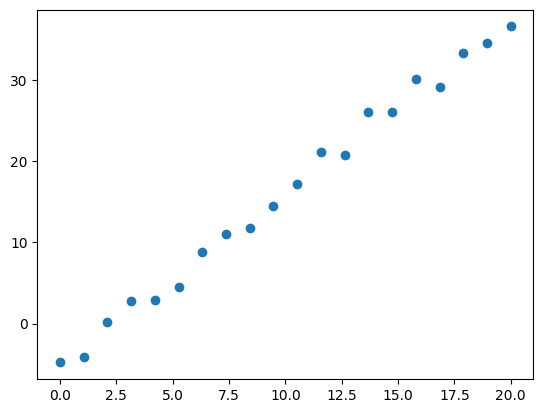

In [124]:
plt.scatter(x,y)

In [125]:
def Model(x, p):
  return p[0] + p[1]*x

In [126]:
p = [1.2,3.5]
_x = np.linspace(np.min(x),np.max(x),100)
_y = Model(_x,p)

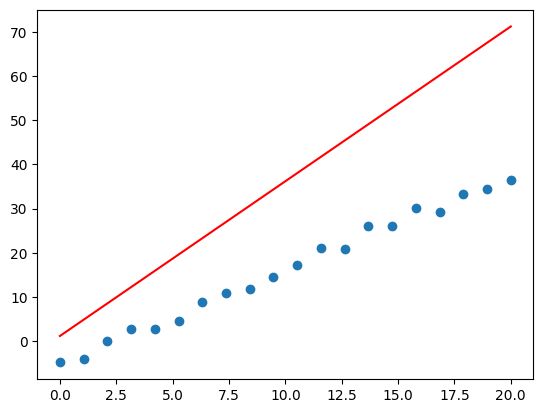

In [127]:
plt.scatter(x,y)
plt.plot(_x,_y,color='r')

In [128]:
def chi2(p):
  return np.sum( (y - Model(x,p))**2  )

In [129]:
chi2([-5.12,2.12])

np.float64(22.923188971835827)

In [130]:
y

array([-4.786585 , -4.06587  ,  0.1796494,  2.719807 ,  2.878523 ,
        4.527426 ,  8.827734 , 10.97722  , 11.79944  , 14.52931  ,
       17.22463  , 21.0981   , 20.79109  , 26.08018  , 26.00302  ,
       30.14533  , 29.14247  , 33.28434  , 34.50524  , 36.56262  ])

In [131]:
theta0 = np.array([1.,1.])

np.sum(x*(y - Model(x,theta0)))

np.float64(1853.2112834741442)

In [132]:
theta0 = np.array([1.,1.])
theta = theta0
thetanew = theta0
gamma = 0.0001

history = np.array([theta0])
historychi = np.array(chi2(theta0))

for i in range(50):
  thetanew[0] = theta[0] + 2*gamma*np.sum(y - Model(x,theta))
  thetanew[1] = theta[1] + 2*gamma*np.sum(x*(y - Model(x,theta)))
  #print(thetanew)
  theta = thetanew
  history = np.vstack((history,thetanew))
  historychi = np.append(historychi,chi2(thetanew))

In [133]:
history[:,1]

array([1.        , 1.36982287, 1.53699196, 1.61270193, 1.64713558,
       1.66294071, 1.67033838, 1.67394144, 1.67583168, 1.67694864,
       1.67771632, 1.6783261 , 1.67886432, 1.67936997, 1.67986063,
       1.68034425, 1.68082442, 1.68130273, 1.68177994, 1.68225636,
       1.68273215, 1.68320737, 1.68368206, 1.68415623, 1.68462988,
       1.68510302, 1.68557565, 1.68604777, 1.68651939, 1.6869905 ,
       1.6874611 , 1.6879312 , 1.68840079, 1.68886988, 1.68933846,
       1.68980654, 1.69027412, 1.69074119, 1.69120776, 1.69167384,
       1.69213941, 1.69260448, 1.69306905, 1.69353312, 1.69399669,
       1.69445977, 1.69492235, 1.69538443, 1.69584601, 1.6963071 ,
       1.6967677 ])

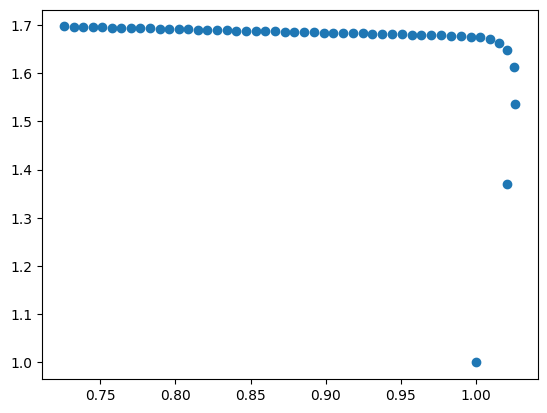

In [134]:
plt.scatter(history[:,0],history[:,1])

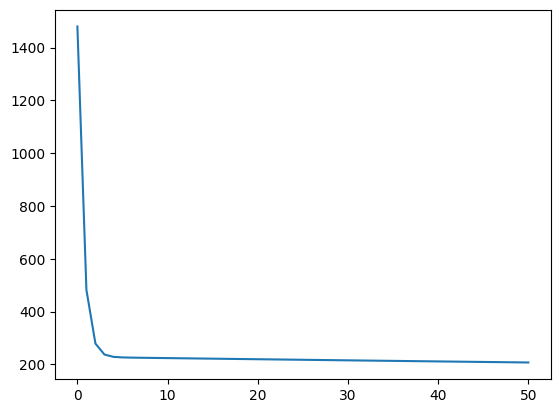

In [135]:
plt.plot(historychi)

In [136]:
thetanew

array([0.72612753, 1.6967677 ])

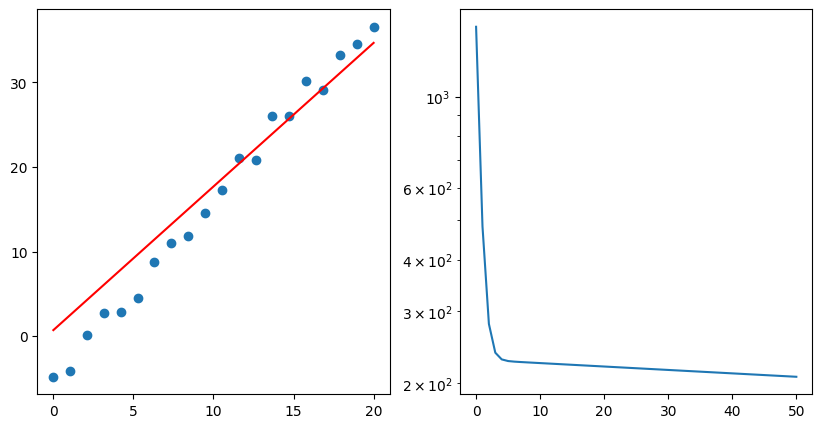

In [137]:
_x = np.linspace(np.min(x),np.max(x),100)
_y = Model(_x,thetanew)
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(121)
ax1 = fig.add_subplot(122)
ax.scatter(x,y)
ax.plot(_x,_y,color='r')
ax1.plot(historychi)
ax1.set_yscale('log')

In [86]:
def f(x,p):
  return p[0]/(p[1]+np.exp(-p[2]*x))

In [100]:
p =np.array([3.1,4.5,1])
x = np.linspace(-10,10,40)
y = f(x,p)
y += np.random.normal(0,0.01,len(x))

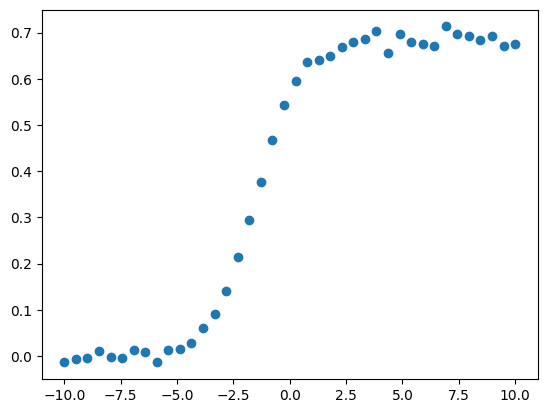

In [108]:
plt.plot(x,y,'o')

In [105]:
A = np.zeros((len(x),2))
A[:,0] = x
A[:,1] = y
A

array([[-1.00000000e+01, -1.42777471e-02],
       [-9.48717949e+00, -5.74093173e-03],
       [-8.97435897e+00, -3.52289269e-03],
       [-8.46153846e+00,  1.10729749e-02],
       [-7.94871795e+00, -1.56059912e-03],
       [-7.43589744e+00, -5.48647086e-03],
       [-6.92307692e+00,  1.36754449e-02],
       [-6.41025641e+00,  7.35504905e-03],
       [-5.89743590e+00, -1.25560223e-02],
       [-5.38461538e+00,  1.31220002e-02],
       [-4.87179487e+00,  1.51010602e-02],
       [-4.35897436e+00,  2.73123068e-02],
       [-3.84615385e+00,  5.98753036e-02],
       [-3.33333333e+00,  9.02858278e-02],
       [-2.82051282e+00,  1.39449465e-01],
       [-2.30769231e+00,  2.13305938e-01],
       [-1.79487179e+00,  2.93975223e-01],
       [-1.28205128e+00,  3.75820383e-01],
       [-7.69230769e-01,  4.68333793e-01],
       [-2.56410256e-01,  5.44267775e-01],
       [ 2.56410256e-01,  5.96065844e-01],
       [ 7.69230769e-01,  6.37404297e-01],
       [ 1.28205128e+00,  6.39743039e-01],
       [ 1.

In [107]:
np.savetxt('DatosSigmoide.txt',A)